# P14 — Razão Treg / T efetora: estímulo (NS × ML) e grupo clínico

**Pergunta.** A razão entre células T reguladoras (Treg) e T CD4⁺ efetoras
(Teff) aumenta ou diminui com o estímulo por *M. leprae* (ML × NS), e é
diferente entre os grupos clínicos (controle, PB, MB, NP)?

**Ponto de partida.** O objeto final do P13 (`dataReseq/analises_previas/P13_objeto_final/reseq_final.h5ad`),
só as células CD4⁺ (sem contaminantes nem baixa qualidade, pela anotação do P09).

**Três definições de Treg e de Teff**, porque elas não concordam sob estímulo
(seção 4):

| fonte | Treg | Teff (ampla) | Teff (estrita) |
| --- | --- | --- | --- |
| anotação (P09) | cluster Treg | memória + ativada + citotóxica | ativada, ativada (Th17), citotóxica, Tem GZMK⁺ |
| atlas L2 (Yasumizu 2024) | TregNaive, TregAct, TregEff | Tcm\*, Tem\*, Temra | Tem\*, Temra, TcmTh0Act |
| NMF (P10, programa dominante) | Treg, Treg efetora | transição, Tcm, Tcm/Tfh, Th17, citotóxica, ativada | ativada, citotóxica |

A definição principal é a da **anotação** com a Teff **ampla** (toda CD4⁺
convencional fora do naive), porque é a anotação usada no resto do projeto.
As outras entram como sensibilidade, lado a lado, sem escolher a que dá o
resultado mais limpo. Também é mostrada a Treg sobre toda a CD4⁺ convencional
(com as naive), que é a "frequência de Treg" mais comum na literatura.

**Estatística.** A unidade é a biblioteca.

* **NS × ML**, pareado dentro do paciente: modelo quasi-binomial
  `Treg de (Treg + Teff) ~ paciente + estímulo`. O odds de Treg contra Teff
  *é* a razão Treg/Teff, então exp(β) é quantas vezes a razão muda com o
  estímulo, ajustada por paciente, com a superdispersão entre bibliotecas
  estimada (φ ≥ 1) e IC pela t com os graus de liberdade residuais. Ao lado, o
  Wilcoxon exato pareado nos log2 das razões e quantos pacientes sobem.
  **HNP44 fica fora do teste**: HNP44_NS tem 95 CD4⁺ e 5 Treg. Restam 6 pares;
  o menor p exato do Wilcoxon com 6 pares é 0,031.
* **Grupos clínicos**: descritivo. MB e NP têm um paciente cada. PB × controle
  (2 × 3 pacientes) tem 10 partições possíveis; o menor p exato bilateral é 0,2,
  então nenhum resultado pode ser "significativo" e só o tamanho do efeito é
  reportado.

In [1]:
import sys
sys.path.insert(0, "/mnt/SATA/singleCellTaru/src/Reseq")

import warnings
warnings.filterwarnings("ignore")

import itertools

import anndata as ad
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats

from functions import config, fmt as F, io, plotting
from functions.issues import IssueLog, show

plotting.apply_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 250)

NB = "analises_previas/P14_razao_treg_tefetora"
log = IssueLog(NB)
INK = plotting.INK
LIBS, PATS = config.LIBRARIES, config.PATIENTS
CLS = config.PATIENT_CLASSIFICATION
PATS_TESTE = [p for p in PATS if p != "HNP44"]
FORA = "HNP44_NS"

a = io.load_data("analises_previas/P13_objeto_final", "reseq_final", "h5ad")
cd4 = a[~a.obs["grupo"].isin(["contaminante", "baixa qualidade"])].copy()
o = cd4.obs
o["library_id"] = o["library_id"].astype(str)
for c in ("grupo", "anotacao", "atlas_L2", "nmf14_rotulo"):
    o[c] = o[c].astype(str)
print(f"{F.n(cd4.n_obs)} células CD4⁺ de {F.n(a.n_obs)} · {plotting.N_DESIGN}")

30.933 células CD4⁺ de 35.247 · 14 bibliotecas · 7 pacientes


## 1. Contagens por biblioteca em cada definição

In [2]:
ATL_TREG = {"TregNaive", "TregAct", "TregEff"}
ATL_NAIVE = {"Tnaive", "TnaiveMX1", "TnaiveAct", "TnaiveSOX4"}
ATL_ESTR = {"TemTh1", "TemTh1pre", "TemTh117", "TemTph", "TemraTh1", "TcmTh0Act"}
NMF_TREG = {"Treg", "Treg efetora (HLA-DR⁺)"}
NMF_AMPLA = {"CD4 transição naive/Tcm", "CD4 Tcm", "CD4 Tcm/Tfh", "CD4 Th17", "CD4 citotóxica (Temra)",
             "CD4 ativada"}
NMF_NAIVE = {"CD4 naive", "CD4 naive IFN⁺"}
NMF_ESTR = {"CD4 ativada", "CD4 citotóxica (Temra)"}
ANOT_ESTR = {"CD4 ativada", "CD4 ativada (Th17)", "CD4 citotóxica (Temra)", "CD4 Tem GZMK⁺"}

g, an_, at, nm = o["grupo"], o["anotacao"], o["atlas_L2"], o["nmf14_rotulo"]
at_ok = at != "nan"
nm_ok = nm.isin(NMF_TREG | NMF_AMPLA | NMF_NAIVE)
FONTES = {"anotação": "anotação (P09)", "atlas": "atlas L2", "NMF": "NMF (P10)"}
DEF = {   # (fonte, Teff): (máscara Treg, máscara Teff)
    ("anotação", "ampla"): (g == "Treg", g.isin(["CD4 memória", "CD4 ativada", "CD4 citotóxica"])),
    ("anotação", "estrita"): (g == "Treg", an_.isin(ANOT_ESTR)),
    ("anotação", "toda CD4 convencional"): (g == "Treg", g != "Treg"),
    ("atlas", "ampla"): (at.isin(ATL_TREG), at_ok & ~at.isin(ATL_TREG | ATL_NAIVE)),
    ("atlas", "estrita"): (at.isin(ATL_TREG), at.isin(ATL_ESTR)),
    ("atlas", "toda CD4 convencional"): (at.isin(ATL_TREG), at_ok & ~at.isin(ATL_TREG)),
    ("NMF", "ampla"): (nm.isin(NMF_TREG), nm.isin(NMF_AMPLA)),
    ("NMF", "estrita"): (nm.isin(NMF_TREG), nm.isin(NMF_ESTR)),
    ("NMF", "toda CD4 convencional"): (nm.isin(NMF_TREG), nm_ok & ~nm.isin(NMF_TREG)),
}
lib = o["library_id"]
lin = []
for (fonte, teff), (mt, me) in DEF.items():
    assert not (mt & me).any()
    nt = mt.groupby(lib).sum().reindex(LIBS)
    ne = me.groupby(lib).sum().reindex(LIBS)
    for L in LIBS:
        lin.append({"fonte": fonte, "Teff": teff, "library_id": L, "paciente": config.patient_of(L),
                    "classificacao": CLS[config.patient_of(L)], "estimulo": L[-2:],
                    "CD4": int((lib == L).sum()), "Treg": int(nt[L]), "Teff_n": int(ne[L])})
cont = pd.DataFrame(lin)


def wilson(k, n, z=1.96):
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h


nn = cont["Treg"] + cont["Teff_n"]
lo, hi = wilson(cont["Treg"], nn)
cont["razao"] = cont["Treg"] / cont["Teff_n"]
cont["razao_ic_inf"] = lo / (1 - lo)
cont["razao_ic_sup"] = hi / (1 - hi)
cont["no_teste"] = cont["library_id"] != FORA
assert (cont["Treg"] > 0).all() and (cont["Teff_n"] > 0).all()
io.save_table(cont, NB, "contagens", description="Treg e Teff por biblioteca em cada definição, com a razão e IC 95% (Wilson)",
              index=False)
principal = cont[(cont["fonte"] == "anotação") & (cont["Teff"] == "ampla")].set_index("library_id")
principal[["CD4", "Treg", "Teff_n", "razao", "razao_ic_inf", "razao_ic_sup"]].round(3)

,CD4,Treg,Teff_n,razao,razao_ic_inf,razao_ic_sup
library_id,,,,,,
CTH92_NS,805,38,450,0.084,0.061,0.117
CTH92_ML,1231,48,793,0.061,0.045,0.081
CTH94_NS,5288,281,3280,0.086,0.076,0.097
CTH94_ML,507,32,315,0.102,0.071,0.146
CTH97_NS,1409,53,997,0.053,0.040,0.070
CTH97_ML,2853,61,2292,0.027,0.021,0.034
PB20_NS,558,15,328,0.046,0.027,0.076
PB20_ML,740,38,410,0.093,0.067,0.129
PB21_NS,3485,221,1757,0.126,0.109,0.145


## 2. Estímulo: a razão Treg/Teff muda com ML?

In [3]:
def efeito_estimulo(d):
    """Quasi-binomial Treg de (Treg + Teff) ~ paciente + estímulo, 6 pares."""
    d = d[d["paciente"].isin(PATS_TESTE)].copy()
    X = pd.get_dummies(d["paciente"], drop_first=True, dtype=float)
    X["ML"] = (d["estimulo"] == "ML").astype(float).to_numpy()
    X = sm.add_constant(X)
    y = np.column_stack([d["Treg"], d["Teff_n"]])
    fit = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    phi = max(1.0, float(fit.pearson_chi2 / fit.df_resid))
    b, se = float(fit.params["ML"]), float(fit.bse["ML"]) * np.sqrt(phi)
    tq = stats.t.ppf(0.975, fit.df_resid)
    p_glm = 2 * stats.t.sf(abs(b / se), fit.df_resid)
    w = d.pivot(index="paciente", columns="estimulo", values="razao")
    l2 = np.log2(w["ML"] / w["NS"])
    p_w = float(stats.wilcoxon(l2, method="exact").pvalue)
    return pd.Series({"ML/NS (modelo)": np.exp(b), "IC inf": np.exp(b - tq * se), "IC sup": np.exp(b + tq * se),
                      "p (quasi-binomial)": p_glm, "phi": phi, "gl resid": fit.df_resid,
                      "p (Wilcoxon exato)": p_w, "pacientes com ML > NS": int((l2 > 0).sum()), "pares": len(l2),
                      **{f"log2 ML/NS {p}": float(v) for p, v in l2.items()}})


ef = cont.groupby(["fonte", "Teff"], sort=False).apply(efeito_estimulo)
pv = ef["p (quasi-binomial)"].sort_values()
ef["p (BH, 9 definições)"] = (pv * len(pv) / np.arange(1, len(pv) + 1))[::-1].cummin()[::-1].clip(upper=1).reindex(ef.index)
io.save_table(ef.reset_index(), NB, "efeito_estimulo",
              description="Mudança da razão Treg/Teff com o estímulo (ML/NS), 6 pares, em cada definição", index=False)
ef[["ML/NS (modelo)", "IC inf", "IC sup", "p (quasi-binomial)", "p (BH, 9 definições)", "p (Wilcoxon exato)",
    "pacientes com ML > NS"]].round(3)

ML/NS (modelo)  IC inf  IC sup  p (quasi-binomial)  p (BH, 9 definições)  p (Wilcoxon exato)  pacientes com ML > NS
fonte    Teff                                                                                                                                      
anotação ampla                           1.091   0.754   1.580               0.570                 0.641               0.844                    4.0
         estrita                         0.742   0.275   2.003               0.475                 0.610               0.562                    3.0
         toda CD4 convencional           1.058   0.788   1.421               0.642                 0.642               0.844                    4.0
atlas    ampla                           1.298   0.894   1.884               0.132                 0.261               0.156                    4.0
         estrita                         1.274   0.888   1.826               0.145                 0.261               0.062                    5.0
         toda CD4 convencional           1.236   0.853   1.791               0.202                 0.303               0.156                    4.0
NMF      ampla                           1.175   1.008   1.370               0.043                 0.129               0.031                    6.0
         estrita                         0.518   0.282   0.952               0.039                 0.129               0.219                    2.0
         toda CD4 convencional           1.238   1.035   1.481               0.028                 0.129               0.031                    6.0

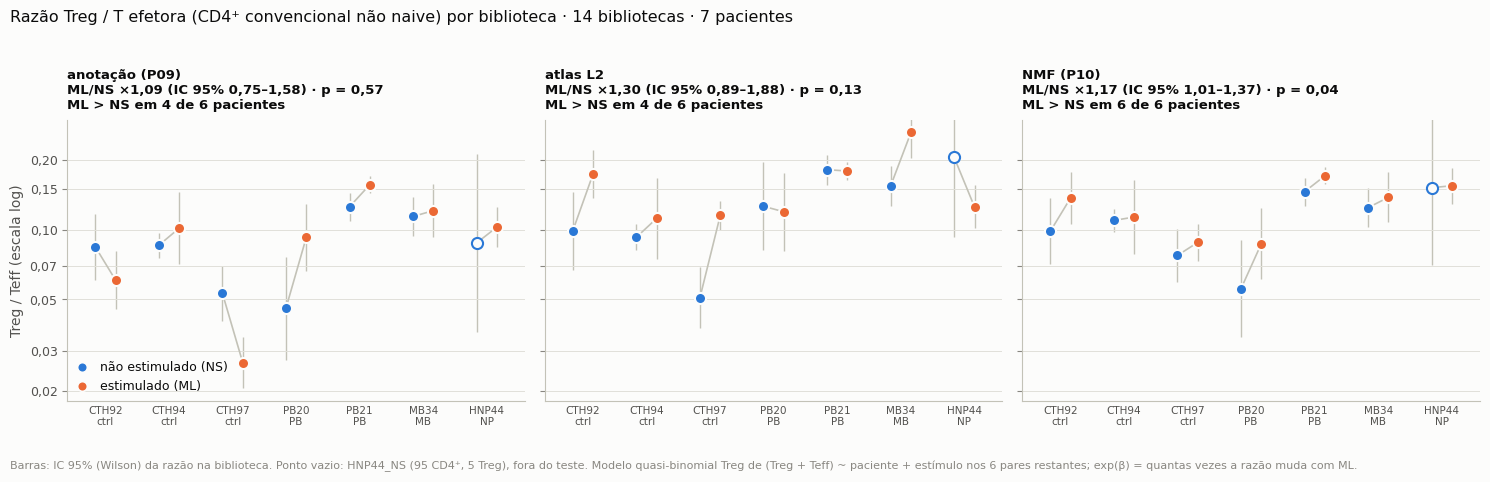

In [4]:
OFF = {"NS": -0.16, "ML": 0.16}
TICKS = [0.02, 0.03, 0.05, 0.07, 0.1, 0.15, 0.2, 0.3, 0.5]


def eixo_log(ax):
    """Ticks fixos e legíveis no eixo y logarítmico, sem mudar os limites."""
    lo, hi = ax.get_ylim()
    ax.set_yticks([t for t in TICKS if lo <= t <= hi])
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 2)))
    ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    ax.set_ylim(lo, hi)


def painel_razao(ax, d, titulo):
    d = d.set_index("library_id")
    xs = {p: i for i, p in enumerate(PATS)}
    for L, r in d.iterrows():
        x = xs[r["paciente"]] + OFF[r["estimulo"]]
        ax.vlines(x, r["razao_ic_inf"], r["razao_ic_sup"], color=INK["axis"], lw=1, zorder=0)
    plotting.paired_dots(ax, d["razao"], log=True)
    r = d.loc[FORA]
    ax.plot(xs["HNP44"] + OFF["NS"], r["razao"], "o", ms=8, mfc=INK["surface"],
            mec=plotting.stim_color(FORA), mew=1.5, zorder=4)
    ax.set_title(titulo, fontsize=9.5)
    ax.tick_params(axis="x", labelsize=7.5)


def titulo_ef(fonte, teff):
    e = ef.loc[(fonte, teff)]
    return (f"{FONTES[fonte]}\nML/NS ×{F.f(e['ML/NS (modelo)'], 2)} (IC 95% {F.f(e['IC inf'], 2)}–"
            f"{F.f(e['IC sup'], 2)}) · p = {F.f(e['p (quasi-binomial)'], 2)}\n"
            f"ML > NS em {int(e['pacientes com ML > NS'])} de {int(e['pares'])} pacientes")


fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for ax, fonte in zip(axes, FONTES):
    painel_razao(ax, cont[(cont["fonte"] == fonte) & (cont["Teff"] == "ampla")], titulo_ef(fonte, "ampla"))
axes[0].set_ylabel("Treg / Teff (escala log)")
eixo_log(axes[0])
plotting.stim_legend(axes[0], loc="lower left")
fig.suptitle(f"Razão Treg / T efetora (CD4⁺ convencional não naive) por biblioteca · {plotting.N_DESIGN}",
             x=0.01, ha="left", fontsize=11.5, color=INK["primary"])
plotting.note(fig, "Barras: IC 95% (Wilson) da razão na biblioteca. Ponto vazio: HNP44_NS (95 CD4⁺, 5 Treg), fora do "
                   "teste. Modelo quasi-binomial Treg de (Treg + Teff) ~ paciente + estímulo nos 6 pares restantes; "
                   "exp(β) = quantas vezes a razão muda com ML.", y=0.0)
fig.tight_layout(rect=(0, 0.04, 1, 0.95))
plotting.savefig(fig, NB, "razao_estimulo", description="Razão Treg/Teff por biblioteca, NS × ML, nas três fontes de rótulo",
                 data=cont[cont["Teff"] == "ampla"], data_index=False)
plt.show()

### Sensibilidade: todas as definições

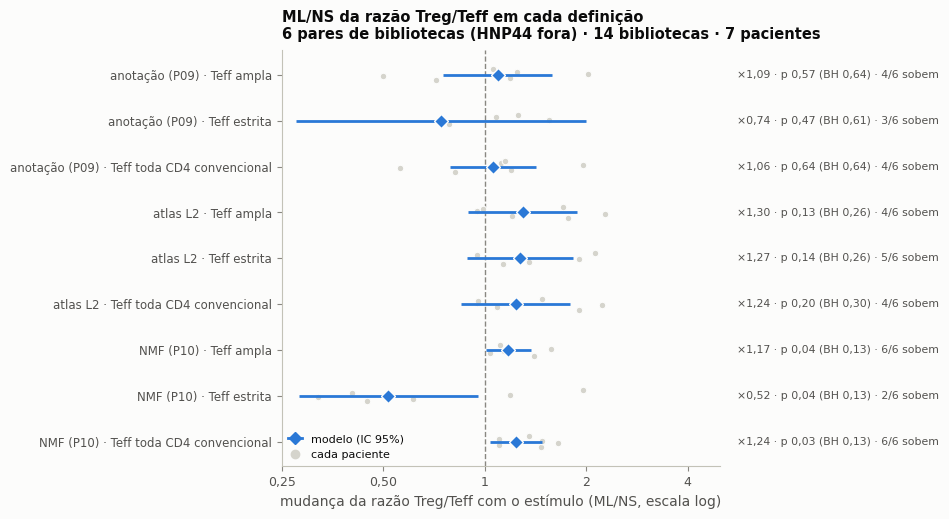

In [5]:
ordem = list(ef.index)[::-1]
fig, ax = plt.subplots(figsize=(8.2, 5.4))
for i, k in enumerate(ordem):
    e = ef.loc[k]
    pts = [2 ** e[f"log2 ML/NS {p}"] for p in PATS_TESTE]
    ax.scatter(pts, np.full(len(pts), i) + np.linspace(-0.12, 0.12, len(pts)), s=22, color=plotting.CONTEXT,
               edgecolor=INK["surface"], lw=0.8, zorder=2)
    ax.hlines(i, e["IC inf"], e["IC sup"], color=plotting.ACCENT, lw=2, zorder=3)
    ax.plot(e["ML/NS (modelo)"], i, "D", ms=7, color=plotting.ACCENT, mec=INK["surface"], mew=1, zorder=4)
    ax.text(5.6, i, f"×{F.f(e['ML/NS (modelo)'], 2)} · p {F.f(e['p (quasi-binomial)'], 2)} "
                    f"(BH {F.f(e['p (BH, 9 definições)'], 2)}) · {int(e['pacientes com ML > NS'])}/6 sobem",
            va="center", fontsize=7.8, color=INK["secondary"])
ax.axvline(1, color=INK["muted"], lw=1, ls="--", zorder=1)
ax.set_xscale("log", base=2)
ax.set_xlim(0.25, 5)
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: F.f(v, 2 if v < 1 else 0)))
ax.set_yticks(range(len(ordem)), [f"{FONTES[f]} · Teff {t}" for f, t in ordem], fontsize=8.5)
ax.set_xlabel("mudança da razão Treg/Teff com o estímulo (ML/NS, escala log)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[mpl.lines.Line2D([], [], marker="D", color=plotting.ACCENT, lw=2, label="modelo (IC 95%)"),
                   mpl.lines.Line2D([], [], marker="o", ls="", color=plotting.CONTEXT, label="cada paciente")],
          loc="lower left", fontsize=8)
ax.set_title(f"ML/NS da razão Treg/Teff em cada definição\n6 pares de bibliotecas (HNP44 fora) · {plotting.N_DESIGN}",
             fontsize=10.5)
fig.subplots_adjust(right=0.66)
plotting.savefig(fig, NB, "sensibilidade_definicoes", description="ML/NS da razão Treg/Teff em todas as definições",
                 data=ef.reset_index(), data_index=False)
plt.show()

### O que isso diz sobre o estímulo

* **Na definição principal, a razão não muda:** ×1,09 (IC 95% 0,75–1,58),
  p = 0,57; sobe em 4 de 6 pacientes.
* **O efeito varia de paciente para paciente.** A razão cai à metade no
  CTH97 (0,053 → 0,027) e cai 28% no CTH92. Dobra no PB20 (0,046 → 0,093),
  sobe 25% no PB21 e fica quase igual no MB34. O CTH97_ML é a biblioteca
  com a resposta de citocinas mais forte do conjunto: o estímulo expande
  muito a CD4 ativada (1.437 células), e a Treg não acompanha.
* **A direção depende do que se chama de Teff.**
  * Com a Teff ampla (toda CD4⁺ convencional não naive) ou com toda a CD4⁺
    convencional, as 6 definições ficam entre ×1,06 e ×1,30, todas acima de 1.
  * Com a Teff estrita (só ativada e citotóxica), a razão cai: ×0,74 na
    anotação e ×0,52 na NMF. O estímulo multiplica a CD4 ativada (de 2,5% para
    4,9% das células, mediana do P09), e o denominador cresce mais que a Treg.
* **Nenhuma definição resiste à correção para as 9 comparações** (menor
  p BH = 0,13). Só as da NMF têm p < 0,05 sem correção, e com sinais opostos
  entre a Teff ampla e a estrita.

**Leitura:** o estímulo por *M. leprae* expande a T efetora ativada mais que
a Treg. Em relação a toda a CD4⁺ de memória, a Treg se mantém ou sobe pouco.
Não há evidência de uma mudança consistente da razão Treg/Teff.

## 3. Grupos clínicos (descritivo)

In [6]:
def grupo_desc(d):
    lin = []
    for est in ("NS", "ML"):
        s = d[(d["estimulo"] == est) & d["no_teste"]].set_index("paciente")["razao"]
        l2 = np.log2(s)
        ctrl = [p for p in s.index if CLS[p] == "controle"]
        pb = [p for p in s.index if CLS[p] == "PB"]
        obs = l2[pb].mean() - l2[ctrl].mean()
        perm = []
        for comb in itertools.combinations(ctrl + pb, len(pb)):
            resto = [p for p in ctrl + pb if p not in comb]
            perm.append(l2[list(comb)].mean() - l2[resto].mean())
        p_perm = float(np.mean(np.abs(perm) >= abs(obs) - 1e-12))
        row = {"estimulo": est, "controle (média geom.)": 2 ** l2[ctrl].mean(),
               "controle mín": s[ctrl].min(), "controle máx": s[ctrl].max(), "PB (média geom.)": 2 ** l2[pb].mean(),
               "PB/controle": 2 ** obs, "p permutação (mín 0,2)": p_perm}
        for p in ("MB34", "HNP44"):
            row[f"{p}"] = s.get(p, np.nan)
            row[f"{p}/controle"] = s.get(p, np.nan) / 2 ** l2[ctrl].mean()
        lin.append(row)
    return pd.DataFrame(lin)


gd = cont.groupby(["fonte", "Teff"], sort=False).apply(grupo_desc).reset_index(level=2, drop=True).reset_index()
io.save_table(gd, NB, "grupos_clinicos", description="Razão Treg/Teff por grupo clínico, NS e ML (descritivo)", index=False)
gd[gd["Teff"] == "ampla"].round(3)

,fonte,Teff,estimulo,controle (média geom.),controle mín,controle máx,PB (média geom.),PB/controle,"p permutação (mín 0,2)",MB34,MB34/controle,HNP44,HNP44/controle
0,anotação,ampla,NS,0.073,0.053,0.086,0.076,1.043,1.0,0.114,1.570,NaN,NaN
1,anotação,ampla,ML,0.055,0.027,0.102,0.121,2.204,0.3,0.121,2.214,0.103,1.879
6,atlas,ampla,NS,0.078,0.051,0.099,0.152,1.957,0.1,0.155,1.996,NaN,NaN
7,atlas,ampla,ML,0.131,0.112,0.175,0.147,1.118,0.5,0.264,2.012,0.126,0.958
12,NMF,ampla,NS,0.094,0.077,0.110,0.090,0.956,0.9,0.125,1.324,NaN,NaN
13,NMF,ampla,ML,0.111,0.088,0.138,0.122,1.098,0.8,0.138,1.243,0.155,1.394


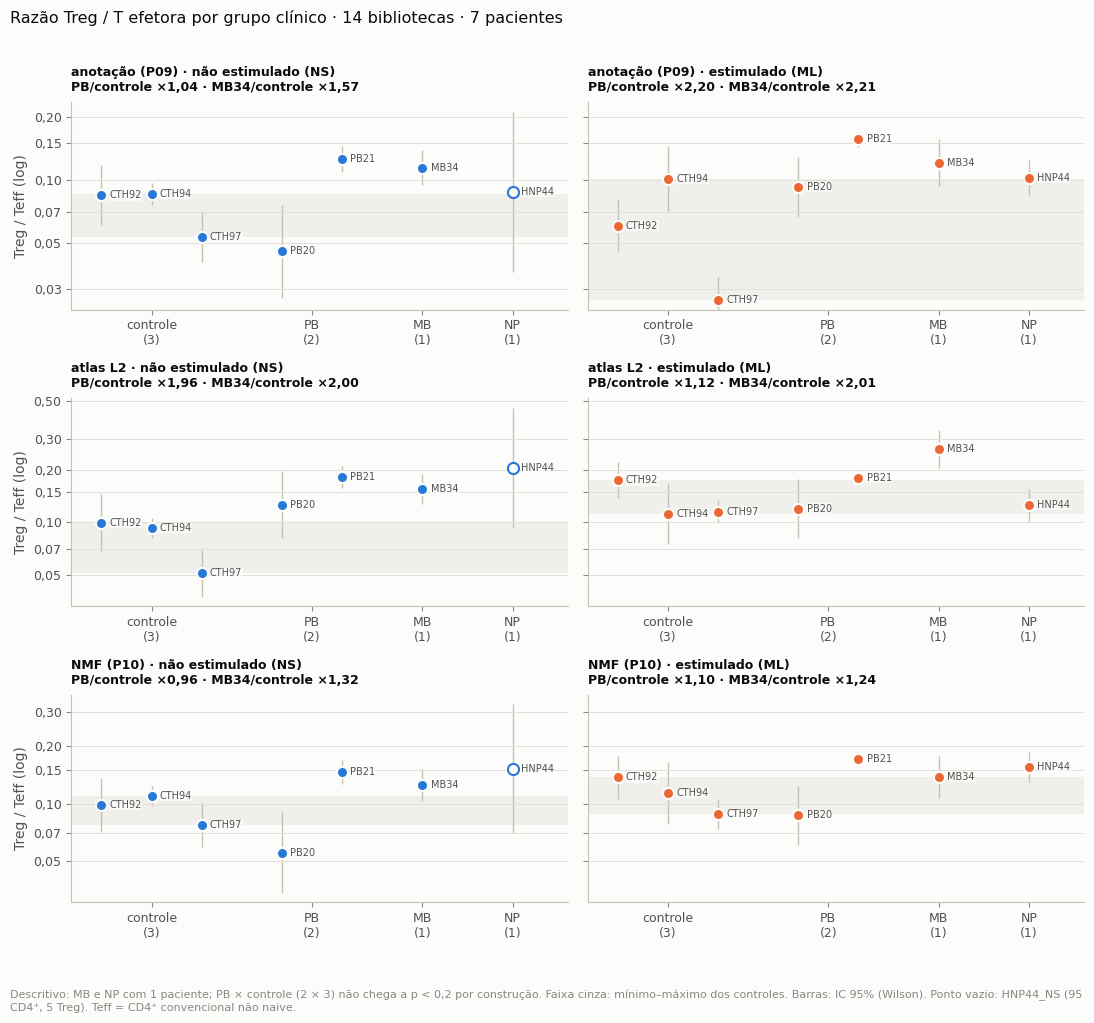

In [7]:
XG = {"controle": 0.0, "PB": 1.6, "MB": 2.7, "NP": 3.6}   # espaço para os rótulos à direita
SPREAD = {"controle": 0.5, "PB": 0.3}
GLAB = {"controle": "controle\n(3)", "PB": "PB\n(2)", "MB": "MB\n(1)", "NP": "NP\n(1)"}
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharey="row")
for i, fonte in enumerate(FONTES):
    d = cont[(cont["fonte"] == fonte) & (cont["Teff"] == "ampla")]
    for j, est in enumerate(("NS", "ML")):
        ax = axes[i][j]
        dd = d[d["estimulo"] == est]
        cor = plotting.STIMULATION_COLORS["nao_estimulado" if est == "NS" else "estimulado"]
        for c in config.CLASSIFICATION_ORDER:
            s = dd[dd["classificacao"] == c].sort_values("paciente")
            xs = XG[c] + np.linspace(-SPREAD.get(c, 0), SPREAD.get(c, 0), len(s)) if len(s) > 1 else np.full(len(s), XG[c])
            for x, (_, r) in zip(xs, s.iterrows()):
                ax.vlines(x, r["razao_ic_inf"], r["razao_ic_sup"], color=INK["axis"], lw=1, zorder=0)
                vazio = r["library_id"] == FORA
                ax.plot(x, r["razao"], "o", ms=8, mfc=INK["surface"] if vazio else cor, mec=cor if vazio else INK["surface"],
                        mew=1.5, zorder=3)
                pos, ha = (6, 0), "left"
                ax.annotate(r["paciente"], (x, r["razao"]), xytext=pos, textcoords="offset points", fontsize=7,
                            color=INK["secondary"], va="center", ha=ha,
                            bbox={"facecolor": INK["surface"], "edgecolor": "none", "pad": 0.3, "alpha": 0.8})
        ref = gd[(gd["fonte"] == fonte) & (gd["Teff"] == "ampla") & (gd["estimulo"] == est)].iloc[0]
        ax.axhspan(ref["controle mín"], ref["controle máx"], color="#f0efec", lw=0, zorder=-1)
        ax.set_xticks([XG[c] for c in config.CLASSIFICATION_ORDER], [GLAB[c] for c in config.CLASSIFICATION_ORDER])
        ax.set_xlim(-0.8, 4.15)
        ax.set_yscale("log")
        ax.grid(axis="x", visible=False)
        ax.set_title(f"{FONTES[fonte]} · {'não estimulado (NS)' if est == 'NS' else 'estimulado (ML)'}\n"
                     f"PB/controle ×{F.f(ref['PB/controle'], 2)} · MB34/controle ×{F.f(ref['MB34/controle'], 2)}",
                     fontsize=9)
    axes[i][0].set_ylabel("Treg / Teff (log)")
    eixo_log(axes[i][0])
fig.suptitle(f"Razão Treg / T efetora por grupo clínico · {plotting.N_DESIGN}", x=0.01, ha="left", fontsize=11.5,
             color=INK["primary"])
plotting.note(fig, "Descritivo: MB e NP com 1 paciente; PB × controle (2 × 3) não chega a p < 0,2 por construção. "
                   "Faixa cinza: mínimo–máximo dos controles. Barras: IC 95% (Wilson). Ponto vazio: HNP44_NS (95 CD4⁺, "
                   "5 Treg). Teff = CD4⁺ convencional não naive.", y=0.0)
fig.tight_layout(rect=(0, 0.035, 1, 0.97))
plotting.savefig(fig, NB, "grupos_clinicos", description="Razão Treg/Teff por grupo clínico, NS e ML, nas três fontes",
                 data=cont[cont["Teff"] == "ampla"], data_index=False)
plt.show()

### O que isso diz sobre os grupos clínicos (descritivo)

* **MB34 fica acima de todos os controles em NS nas três fontes**: ×1,57 na
  anotação, ×2,00 no atlas e ×1,32 na NMF, sobre a média geométrica dos
  controles. Em ML, fica acima na anotação e no atlas e empata com o controle
  mais alto na NMF (0,138 contra 0,138 do CTH92_ML). Isso combina
  com o que se descreve no polo multibacilar/lepromatoso, mais Treg (Palermo et
  al., 2012, *Am J Trop Med Hyg* 86:878). Mas é **um paciente**: é uma
  hipótese, não um resultado.
* **PB não tem um padrão próprio.** O PB21 fica acima dos controles nas três
  fontes. O PB20 fica abaixo deles na anotação e na NMF, e acima no atlas.
  PB/controle vai de ×0,96 a ×1,96 em NS, conforme a fonte. Em ML, o ×2,20 da anotação vem da queda do CTH97_ML, e
  não de um aumento no PB. No atlas e na NMF, o PB/controle em ML fica em
  ×1,1.
* **NP (HNP44):** o NS não tem células suficientes (5 Treg). Em ML, o HNP44
  fica dentro da faixa dos controles ou logo acima, conforme a fonte.
* Nenhuma comparação entre grupos pode ser testada: PB × controle não chega a
  p < 0,2 por construção, e MB e NP têm um paciente cada.

## 4. Por que as fontes discordam no estímulo: FOXP3 fora do cluster Treg

Células T convencionais humanas ativadas expressam FOXP3 e CD25 (IL2RA) de
forma transitória, sem virar Treg (Wang et al., 2007, *Eur J Immunol*
37:129; Allan et al., 2007, *Int Immunol* 19:345). Helios (IKZF2) e RTKN2
marcam a Treg estável e quase não sobem na ativação. Se o estímulo cria
células FOXP3⁺ IL2RA⁺ Helios⁻, uma régua que pesa FOXP3/IL2RA (o atlas)
conta essas células como Treg, e a anotação por cluster as deixa em
"CD4 ativada".

In [8]:
GENES = ["FOXP3", "IL2RA", "IKZF2", "RTKN2", "CTLA4", "IL7R"]
det = pd.DataFrame(cd4[:, GENES].layers["counts"].toarray() > 0, columns=GENES, index=cd4.obs_names)
est = o["library_id"].str[-2:]
atl_treg = o["atlas_L2"].isin(ATL_TREG)
POPS = {"cluster Treg": g == "Treg",
        "Treg só no atlas": atl_treg & (g != "Treg"),
        "CD4 ativada, não Treg no atlas": (g == "CD4 ativada") & ~atl_treg}
marc = pd.DataFrame({(pop, e): det[(m & (est == e)).to_numpy()].mean() for pop, m in POPS.items()
                     for e in ("NS", "ML")}).T
marc["células"] = [int((m & (est == e)).sum()) for pop, m in POPS.items() for e in ("NS", "ML")]
io.save_table(marc.reset_index().rename(columns={"level_0": "populacao", "level_1": "estimulo"}), NB, "marcadores_treg",
              description="Fração de células que detectam cada marcador de Treg, por população e estímulo", index=False)

foxp = det["FOXP3"].to_numpy()
fora = pd.Series({L: float(((g != "Treg") & foxp & (lib == L)).sum() / max(1, (foxp & (lib == L)).sum()))
                  for L in LIBS})
atl_fora = pd.Series({L: float((atl_treg & (g != "Treg") & (lib == L)).sum() / max(1, (atl_treg & (lib == L)).sum()))
                      for L in LIBS})
fx = pd.DataFrame({"FOXP3+ fora do cluster Treg": fora, "Treg do atlas fora do cluster Treg": atl_fora,
                   "FOXP3+ (células)": pd.Series({L: int((foxp & (lib == L)).sum()) for L in LIBS})})
io.save_table(fx, NB, "foxp3_fora_do_cluster", description="Por biblioteca: fração das FOXP3+ e das Treg do atlas fora do cluster Treg")
marc.round(3)

FOXP3  IL2RA  IKZF2  RTKN2  CTLA4   IL7R  células
cluster Treg                   NS  0.717  0.508  0.812  0.729  0.587  0.738      728
                               ML  0.843  0.866  0.757  0.738  0.644  0.408     1005
Treg só no atlas               NS  0.456  0.235  0.485  0.529  0.324  0.853       68
                               ML  0.535  0.724  0.209  0.256  0.339  0.520      254
CD4 ativada, não Treg no atlas NS  0.071  0.128  0.028  0.167  0.243  0.972      563
                               ML  0.156  0.533  0.032  0.115  0.230  0.708     2418

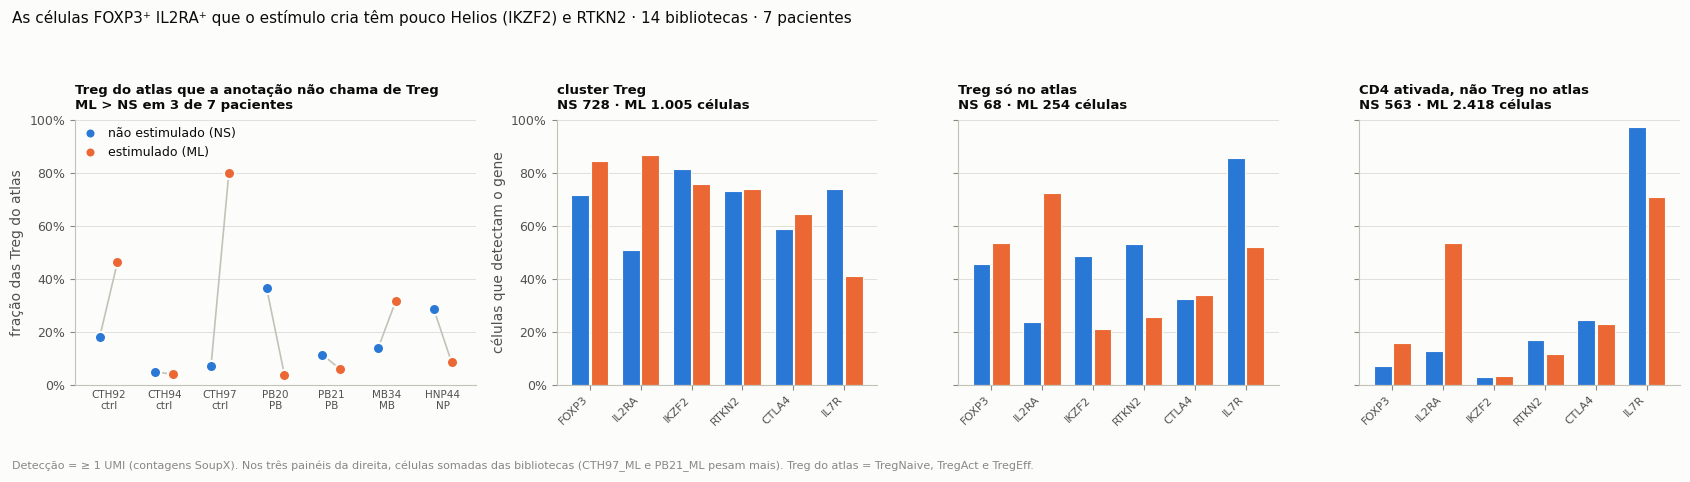

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.25, 1, 1, 1]})
a1 = axs[0]
plotting.paired_dots(a1, fx["Treg do atlas fora do cluster Treg"])
plotting.percent(a1, "y")
a1.set_ylim(0, 1)
a1.tick_params(axis="x", labelsize=7.5)
w = fx["Treg do atlas fora do cluster Treg"]
sob = sum(w[f"{p}_ML"] > w[f"{p}_NS"] for p in PATS)
a1.set_title(f"Treg do atlas que a anotação não chama de Treg\nML > NS em {sob} de 7 pacientes", fontsize=9.5)
a1.set_ylabel("fração das Treg do atlas")
plotting.stim_legend(a1, loc="upper left")
xb = np.arange(len(GENES))
wd = 0.38
for ax, pop in zip(axs[1:], POPS):
    for e, dx in (("NS", -wd / 2), ("ML", wd / 2)):
        s = "nao_estimulado" if e == "NS" else "estimulado"
        ax.bar(xb + dx, marc.loc[(pop, e), GENES].to_numpy(float), width=wd * 0.92,
               color=plotting.STIMULATION_COLORS[s], edgecolor=INK["surface"], lw=0.8)
    ax.set_xticks(xb, GENES, rotation=45, ha="right", fontsize=8)
    ax.set_ylim(0, 1)
    plotting.percent(ax, "y")
    ax.grid(axis="x", visible=False)
    ax.set_title(f"{pop}\nNS {F.n(marc.loc[(pop, 'NS'), 'células'])} · ML {F.n(marc.loc[(pop, 'ML'), 'células'])} células",
                 fontsize=9.5)
axs[1].set_ylabel("células que detectam o gene")
for ax in axs[2:]:
    ax.tick_params(axis="y", labelleft=False)
fig.suptitle(f"As células FOXP3⁺ IL2RA⁺ que o estímulo cria têm pouco Helios (IKZF2) e RTKN2 · {plotting.N_DESIGN}",
             x=0.01, ha="left", fontsize=11, color=INK["primary"])
plotting.note(fig, "Detecção = ≥ 1 UMI (contagens SoupX). Nos três painéis da direita, células somadas das bibliotecas "
                   "(CTH97_ML e PB21_ML pesam mais). Treg do atlas = TregNaive, TregAct e TregEff.", y=0.0)
fig.tight_layout(rect=(0, 0.04, 1, 0.92))
plotting.savefig(fig, NB, "foxp3_fora_do_cluster", description="Treg do atlas fora do cluster Treg e marcadores por população",
                 data=marc.reset_index().rename(columns={"level_0": "populacao", "level_1": "estimulo"}), data_index=False)
plt.show()

### O que isso diz

* No CTH97_ML, **80% das Treg do atlas estão fora do cluster Treg**, contra 7%
  no CTH97_NS. Isso também acontece, em menor grau, no CTH92 e no MB34. Nos
  outros pacientes, a fração cai com o estímulo.
* Em ML, as células que só o atlas chama de Treg detectam FOXP3 (54%) e IL2RA
  (72%). Mas detectam pouco Helios (IKZF2, 21%) e RTKN2 (26%), contra 76% e
  74% no cluster Treg. É o perfil de T convencional ativada com FOXP3
  transitório. Existem Treg Helios⁻ (uma parte das Treg humanas), então não
  dá para descartar que algumas sejam Treg verdadeiras.
* **Consequência:** o atlas tende a contar células ativadas como Treg nas
  bibliotecas mais estimuladas. Isso infla a Treg em ML e explica o ×1,30 do
  atlas contra o ×1,09 da anotação. A anotação por cluster é mais
  conservadora. A medida definitiva seria citometria (FOXP3, Helios, CD127,
  CD25) nas mesmas amostras.

## 5. Treg efetora dentro da Treg

Se a pergunta for a fração de Treg efetora (ativada, HLA-DR⁺ CD39⁺) dentro da
Treg, ela está no atlas (TregAct + TregEff sobre toda Treg) e na NMF
(programa Treg efetora sobre Treg + Treg efetora). A anotação não separa a Treg.

In [10]:
ET = []
for fonte, mt, me in (("atlas", at.isin(ATL_TREG), at.isin({"TregAct", "TregEff"})),
                      ("NMF", nm.isin(NMF_TREG), nm == "Treg efetora (HLA-DR⁺)")):
    for L in LIBS:
        k_, n_ = int((me & (lib == L)).sum()), int((mt & (lib == L)).sum())
        lo_, hi_ = wilson(k_, n_)
        ET.append({"fonte": fonte, "library_id": L, "paciente": config.patient_of(L), "estimulo": L[-2:],
                   "Treg": n_, "Treg efetora": k_, "fracao": k_ / n_, "ic_inf": lo_, "ic_sup": hi_})
et = pd.DataFrame(ET)
ef_et = []
for fonte, d in et.groupby("fonte", sort=False):
    dd = d[d["paciente"].isin(PATS_TESTE)].rename(columns={"Treg efetora": "Treg_", "Treg": "tot"})
    dd = dd.assign(Treg=dd["Treg_"], Teff_n=dd["tot"] - dd["Treg_"], razao=dd["Treg_"] / (dd["tot"] - dd["Treg_"]))
    e = efeito_estimulo(dd)
    w = d.pivot(index="paciente", columns="estimulo", values="fracao")
    ef_et.append({"fonte": fonte, "odds ML/NS (modelo)": e["ML/NS (modelo)"], "IC inf": e["IC inf"],
                  "IC sup": e["IC sup"], "p (quasi-binomial)": e["p (quasi-binomial)"],
                  "pacientes com ML > NS": int((w.loc[PATS_TESTE, "ML"] > w.loc[PATS_TESTE, "NS"]).sum()),
                  "mediana NS": float(w.loc[PATS_TESTE, "NS"].median()),
                  "mediana ML": float(w.loc[PATS_TESTE, "ML"].median())})
ef_et = pd.DataFrame(ef_et).set_index("fonte")
io.save_table(et, NB, "treg_efetora", description="Fração de Treg efetora dentro da Treg, por biblioteca", index=False)
io.save_table(ef_et, NB, "efeito_estimulo_treg_efetora", description="Mudança da fração de Treg efetora com o estímulo, 6 pares")
ef_et.round(3)

,odds ML/NS (modelo),IC inf,IC sup,p (quasi-binomial),pacientes com ML > NS,mediana NS,mediana ML
fonte,,,,,,,
atlas,1.741,0.937,3.235,0.070,6,0.715,0.777
NMF,1.144,0.575,2.276,0.637,3,0.419,0.485


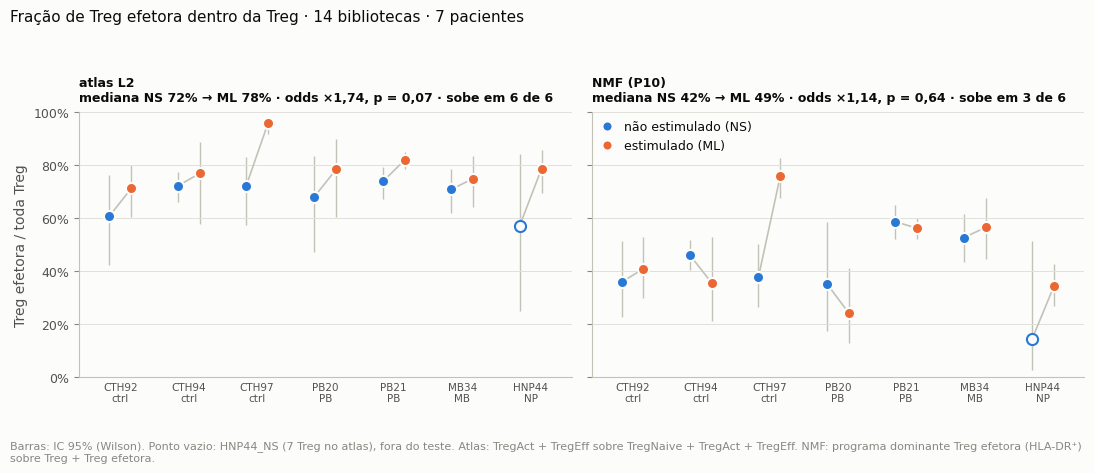

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, (fonte, d) in zip(axes, et.groupby("fonte", sort=False)):
    d = d.set_index("library_id")
    xs = {p: i for i, p in enumerate(PATS)}
    for L, r in d.iterrows():
        ax.vlines(xs[r["paciente"]] + OFF[r["estimulo"]], r["ic_inf"], r["ic_sup"], color=INK["axis"], lw=1, zorder=0)
    plotting.paired_dots(ax, d["fracao"])
    r = d.loc[FORA]
    ax.plot(xs["HNP44"] + OFF["NS"], r["fracao"], "o", ms=8, mfc=INK["surface"], mec=plotting.stim_color(FORA), mew=1.5,
            zorder=4)
    e = ef_et.loc[fonte]
    ax.set_title(f"{FONTES[fonte]}\nmediana NS {F.pct(e['mediana NS'], 0)} → ML {F.pct(e['mediana ML'], 0)} · "
                 f"odds ×{F.f(e['odds ML/NS (modelo)'], 2)}, p = {F.f(e['p (quasi-binomial)'], 2)} · "
                 f"sobe em {int(e['pacientes com ML > NS'])} de 6", fontsize=9)
    plotting.percent(ax, "y")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelsize=7.5)
axes[0].set_ylabel("Treg efetora / toda Treg")
plotting.stim_legend(axes[-1], loc="upper left")
fig.suptitle(f"Fração de Treg efetora dentro da Treg · {plotting.N_DESIGN}", x=0.01, ha="left", fontsize=11,
             color=INK["primary"])
plotting.note(fig, "Barras: IC 95% (Wilson). Ponto vazio: HNP44_NS (7 Treg no atlas), fora do teste. Atlas: TregAct + "
                   "TregEff sobre TregNaive + TregAct + TregEff. NMF: programa dominante Treg efetora (HLA-DR⁺) sobre "
                   "Treg + Treg efetora.", y=0.0)
fig.tight_layout(rect=(0, 0.05, 1, 0.93))
plotting.savefig(fig, NB, "treg_efetora", description="Fração de Treg efetora dentro da Treg, NS × ML", data=et,
                 data_index=False)
plt.show()

### O que isso diz

* **Atlas:** a Treg efetora vai de 72% para 78% da Treg (medianas), sobe em
  6 de 6 pacientes, odds ×1,74, p = 0,07. Boa parte vem do CTH97_ML, que chega
  a 96%: são as mesmas células FOXP3⁺ ativadas da seção 4.
* **NMF:** de 42% para 49%, sobe em 3 de 6, p = 0,64.
* Não há aumento consistente da Treg efetora com o estímulo.

## Resumo

1. **NS × ML:** a razão Treg/Teff **não muda de forma consistente** com o
   estímulo. Na definição principal, ×1,09 (0,75–1,58), p = 0,57. O estímulo
   expande mais a T efetora ativada que a Treg. Por isso a razão contra a Teff
   estrita cai (×0,52–0,74), e a razão contra toda a CD4⁺ de memória fica
   estável ou sobe pouco (×1,06–1,30). Nada resiste à correção para as 9
   definições.
2. **Heterogeneidade:** o efeito do estímulo varia por paciente. O CTH97, o
   controle que mais responde, perde metade da razão; o PB20 dobra.
3. **Grupos clínicos (descritivo):** em NS, o MB34 tem a razão acima de
   todos os controles nas três fontes. Em ML, fica acima em duas e empata na
   terceira. É uma hipótese para testar com mais pacientes MB. O PB não se
   separa dos controles.
4. **Cuidado com a régua sob estímulo:** células FOXP3⁺ IL2RA⁺ Helios⁻ da
   ativação entram como Treg no atlas e não na anotação.

## Problemas encontrados

In [12]:
e_an, e_at = ef.loc[("anotação", "ampla")], ef.loc[("atlas", "ampla")]
atl = cont[(cont["fonte"] == "atlas") & (cont["Teff"] == "ampla")].set_index("library_id")
n_atl_cth97 = int(atl.loc["CTH97_ML", "Treg"])
log.add("MAJOR", "seção 4", "As fontes de rótulo discordam sobre a Treg nas bibliotecas estimuladas",
        evidence=f"ML/NS da razão: anotação ×{F.f(e_an['ML/NS (modelo)'], 2)}, atlas ×{F.f(e_at['ML/NS (modelo)'], 2)}. "
                 f"CTH97_ML: {int(principal.loc['CTH97_ML', 'Treg'])} Treg na anotação contra "
                 f"{n_atl_cth97} no atlas",
        impact="A direção do efeito do estímulo depende da régua; células FOXP3⁺ IL2RA⁺ Helios⁻ do estímulo podem ser "
               "T convencional ativada",
        recommendation="Reportar as três réguas; para Treg estável, exigir IKZF2/RTKN2 ou citometria (FOXP3, Helios, "
                       "CD127) nas mesmas amostras")
log.add("MAJOR", "seção 3", "Grupos clínicos sem poder de teste",
        evidence="MB e NP com 1 paciente; PB × controle 2 × 3, menor p exato bilateral 0,2",
        impact="Diferenças entre grupos são só descritivas", recommendation="Não afirmar diferença entre grupos")
log.add("MINOR", "seções 2 e 5", "HNP44 fora do teste do estímulo",
        evidence=f"HNP44_NS: {int(principal.loc[FORA, 'CD4'])} CD4⁺, {int(principal.loc[FORA, 'Treg'])} Treg",
        impact="Teste com 6 pares; o menor p exato do Wilcoxon é 0,031", recommendation="Mostrar HNP44 sem testar")
log.add("INFO", "seção 2", "Unidade de análise = biblioteca",
        evidence="Quasi-binomial com paciente fixo e φ estimado; nenhuma célula tratada como réplica",
        impact="Evita pseudorreplicação", recommendation="—")
show(log.save())

severity,location,problem,evidence,impact,recommendation
MAJOR,seção 4,As fontes de rótulo discordam sobre a Treg nas bibliotecas estimuladas,"ML/NS da razão: anotação ×1,09, atlas ×1,30. CTH97_ML: 61 Treg na anotação contra 192 no atlas",A direção do efeito do estímulo depende da régua; células FOXP3⁺ IL2RA⁺ Helios⁻ do estímulo podem ser T convencional ativada,"Reportar as três réguas; para Treg estável, exigir IKZF2/RTKN2 ou citometria (FOXP3, Helios, CD127) nas mesmas amostras"
MAJOR,seção 3,Grupos clínicos sem poder de teste,"MB e NP com 1 paciente; PB × controle 2 × 3, menor p exato bilateral 0,2",Diferenças entre grupos são só descritivas,Não afirmar diferença entre grupos
MINOR,seções 2 e 5,HNP44 fora do teste do estímulo,"HNP44_NS: 95 CD4⁺, 5 Treg","Teste com 6 pares; o menor p exato do Wilcoxon é 0,031",Mostrar HNP44 sem testar
INFO,seção 2,Unidade de análise = biblioteca,Quasi-binomial com paciente fixo e φ estimado; nenhuma célula tratada como réplica,Evita pseudorreplicação,—
